In [1]:
pip install yfinance

Note: you may need to restart the kernel to use updated packages.


In [2]:
pip install pandas

Note: you may need to restart the kernel to use updated packages.


[*********************100%***********************]  1 of 1 completed



First 5 rows:
Price            Close        High         Low        Open   Volume
Ticker         INFY.NS     INFY.NS     INFY.NS     INFY.NS  INFY.NS
Date                                                               
2020-01-01  619.740295  622.389677  616.123717  618.184342  2112415
2020-01-02  617.931946  623.062434  614.735901  621.464438  5658200
2020-01-03  627.436096  629.118230  617.259204  617.259204  7882938
2020-01-06  621.422363  633.996326  619.445876  627.520099  6519403
2020-01-07  612.212769  624.576414  609.857740  620.707526  7899363

Dataset shape: (1677, 5)

Training samples: 1334
Testing samples: 334

Model training completed!

----- Infosys Model Performance -----
MAE  : 11.338002429033137
MSE  : 208.07237244683378
RMSE : 14.424713946794016
R2   : 0.9944451191793721


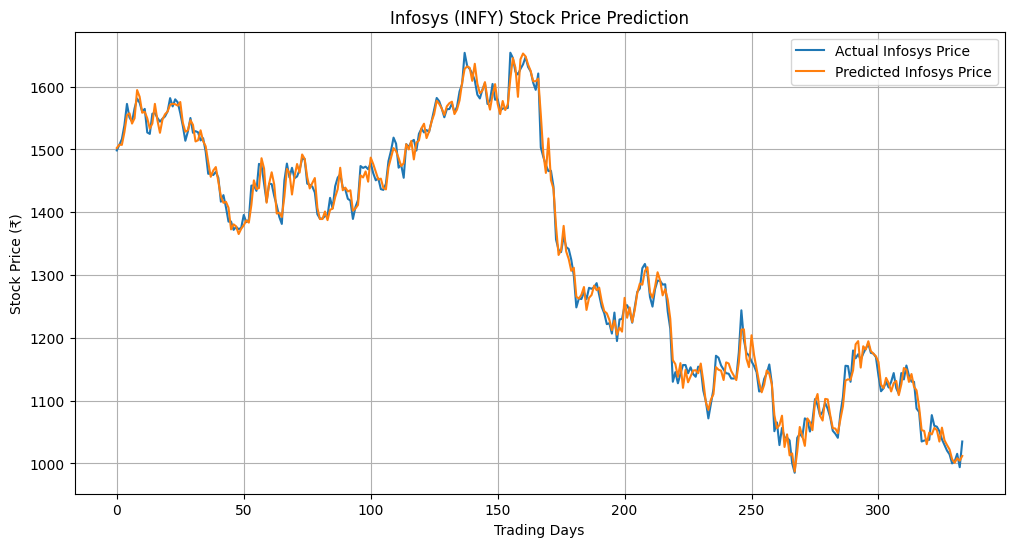


----- Infosys Next Day Prediction -----
Predicted Closing Price: ₹ 1004.538886577749


C:\Users\madhu\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2742: UserWarning: X has feature names, but LinearRegression was fitted without feature names
  warnings.warn(
C:\Users\madhu\anaconda3\Lib\site-packages\sklearn\utils\_array_api.py:757: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  array = numpy.asarray(array, order=order, dtype=dtype)
C:\Users\madhu\AppData\Local\Temp\ipykernel_16860\366487165.py:181: DeprecationWarning: Conversion of an array with ndim > 0 to a scalar is deprecated, and will error in future. Ensure you extract a single element from your array before performing this operation. (Deprecated NumPy 1.25.)
  float(next_price[0])


In [3]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score


# -----------------------------------
# 1. Download Infosys Stock Data
# -----------------------------------

ticker = "INFY.NS"

print("Downloading Infosys stock data...")

data = yf.download(
    ticker,
    start="2020-01-01",
    auto_adjust=True
)

print("\nFirst 5 rows:")
print(data.head())


# -----------------------------------
# 2. Clean Data
# -----------------------------------

data = data.dropna()

print("\nDataset shape:", data.shape)


# -----------------------------------
# 3. Create Features
# -----------------------------------

data["Previous_Close"] = data["Close"].shift(1)
data["Previous_2_Close"] = data["Close"].shift(2)
data["Previous_3_Close"] = data["Close"].shift(3)

data["MA_5"] = data["Close"].rolling(5).mean()
data["MA_10"] = data["Close"].rolling(10).mean()

data = data.dropna()


# -----------------------------------
# 4. Select Features
# -----------------------------------

features = [
    "Previous_Close",
    "Previous_2_Close",
    "Previous_3_Close",
    "MA_5",
    "MA_10",
    "Volume"
]

X = data[features]
y = data["Close"]


# -----------------------------------
# 5. Train-Test Split
# -----------------------------------

split = int(len(data) * 0.8)

X_train = X.iloc[:split]
X_test = X.iloc[split:]

y_train = y.iloc[:split]
y_test = y.iloc[split:]

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))


# -----------------------------------
# 6. Train Machine Learning Model
# -----------------------------------

model = LinearRegression()

model.fit(X_train, y_train)

print("\nModel training completed!")


# -----------------------------------
# 7. Make Predictions
# -----------------------------------

y_pred = model.predict(X_test)


# -----------------------------------
# 8. Evaluate Model
# -----------------------------------

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("\n----- Infosys Model Performance -----")

print("MAE  :", mae)
print("MSE  :", mse)
print("RMSE :", rmse)
print("R2   :", r2)


# -----------------------------------
# 9. Plot Actual vs Predicted
# -----------------------------------

plt.figure(figsize=(12, 6))

plt.plot(
    y_test.values,
    label="Actual Infosys Price"
)

plt.plot(
    y_pred,
    label="Predicted Infosys Price"
)

plt.title("Infosys (INFY) Stock Price Prediction")

plt.xlabel("Trading Days")

plt.ylabel("Stock Price (₹)")

plt.legend()

plt.grid(True)

plt.show()


# -----------------------------------
# 10. Predict Next Closing Price
# -----------------------------------

latest_close = data["Close"].iloc[-1]
previous_close = data["Close"].iloc[-2]
previous_2_close = data["Close"].iloc[-3]

ma_5 = data["Close"].tail(5).mean()
ma_10 = data["Close"].tail(10).mean()

volume = data["Volume"].iloc[-1]


next_day = pd.DataFrame({
    "Previous_Close": [latest_close],
    "Previous_2_Close": [previous_close],
    "Previous_3_Close": [previous_2_close],
    "MA_5": [ma_5],
    "MA_10": [ma_10],
    "Volume": [volume]
})


next_price = model.predict(next_day)

print("\n----- Infosys Next Day Prediction -----")

print(
    "Predicted Closing Price: ₹",
    float(next_price[0])
)